**Name:** Ibrahim Khaled Al-Khamis

**Id:** 2240004075

**Section:** 7MA01

**Course:**   ARTI 403 – Image Processing

---
# Lab 7(A): Laplacian Filter

### 1: Import Libraries

In [11]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
plt.rc('text', usetex=False)


### 2: Laplacian Filter Using a Manual Kernel

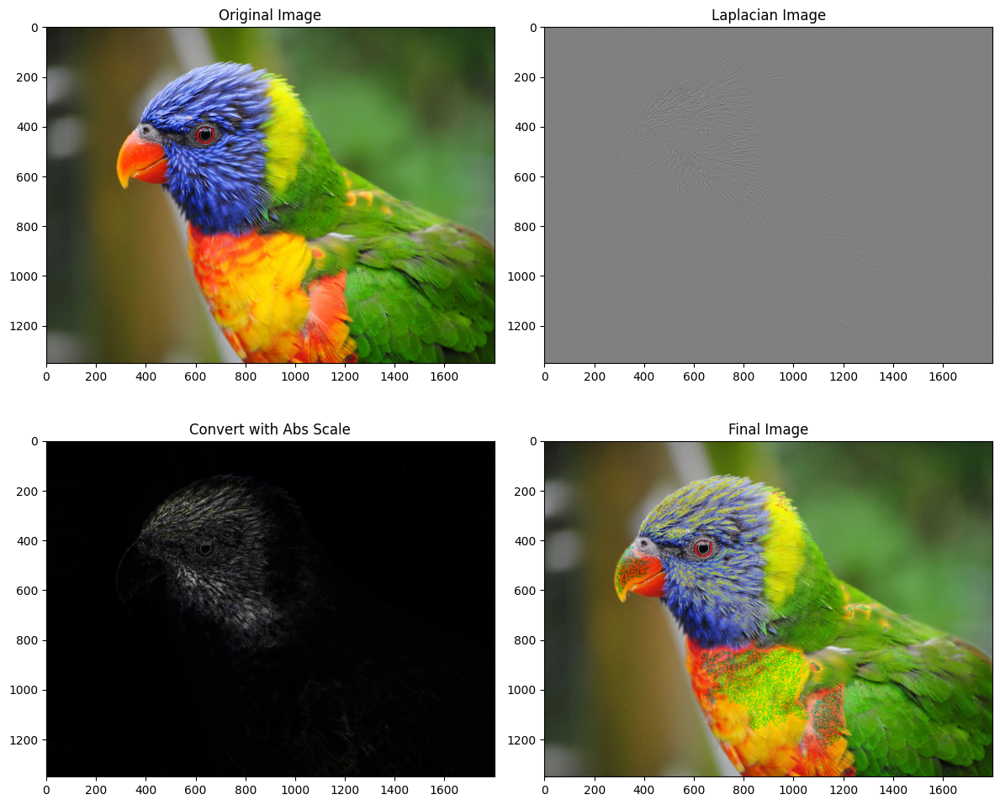

In [16]:
# Laplacian Filter - Manual Kernel

imgFile = 'color_image.jpg'
img_bgr = cv2.imread(imgFile)
if img_bgr is None:
    raise FileNotFoundError(f'Image not found: {imgFile}')
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)
finalImage = img + laplacian_abs
# Display the signed Laplacian in a visible color range.
laplacian_view = np.clip(laplacian_manual + 128, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_view), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage), plt.title('Final Image')
plt.tight_layout()
plt.show()


### 3: Laplacian Filter Using OpenCV


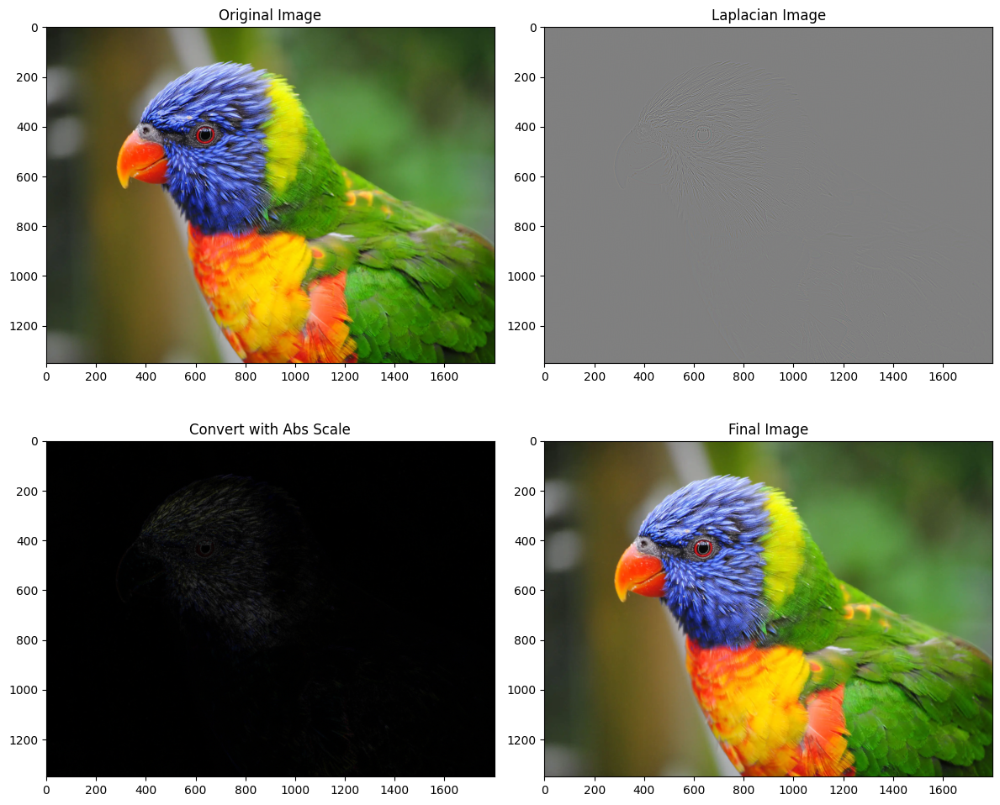

In [25]:
# Laplacian Filter - OpenCV Function

blurred = cv2.GaussianBlur(img, (3, 3), 0)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)
laplacian_8bit = cv2.convertScaleAbs(laplacian)
finalImage2 = cv2.add(img, laplacian_8bit)

laplacian_view2 = np.clip(laplacian + 128, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_view2), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2), plt.title('Final Image')
plt.tight_layout()
plt.show()


---
# Lab 7(B): Mathematical and Statistical Filters

### 1: Add Noise to the Color Image

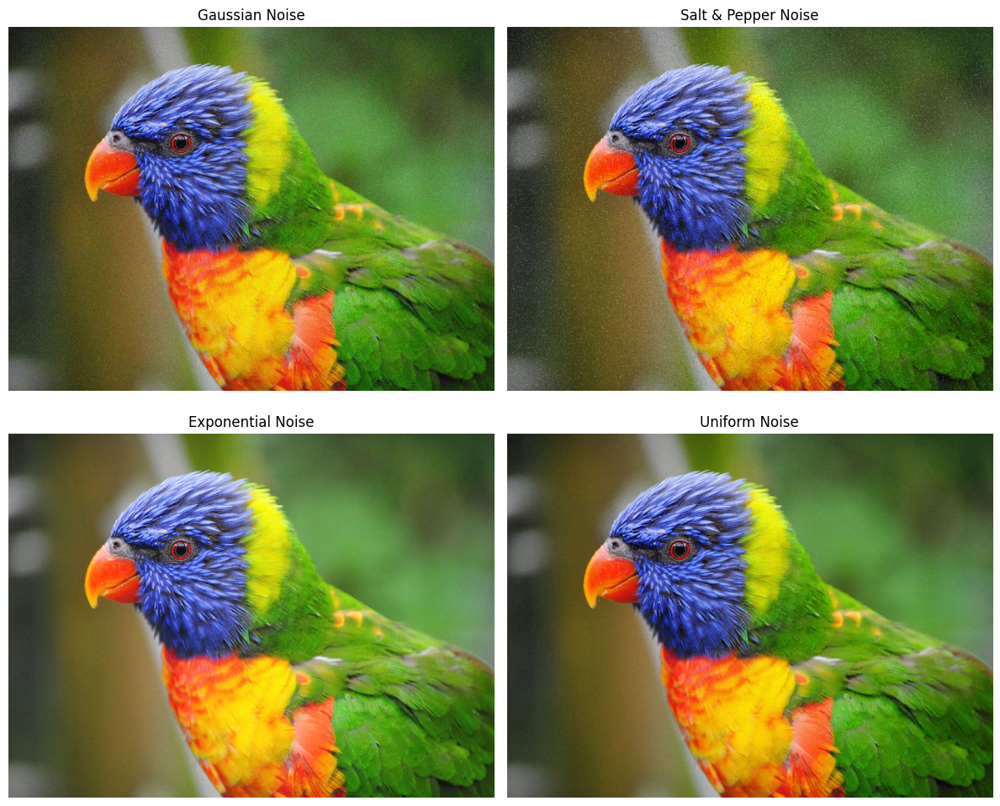

In [18]:
# Adding Noise to a Color Image

imgPath = 'color_image.jpg'
img_bgr = cv2.imread(imgPath)
if img_bgr is None:
    raise FileNotFoundError(f'Image not found: {imgPath}')
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def add_noise(image, noise_type):
    row, col, channels = image.shape

    if noise_type == 'gaussian':
        mean = 0
        var = 0.01
        sigma = var ** 0.5
        gauss = np.random.normal(mean, sigma, (row, col, channels))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == 'salt_pepper':
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        num_salt = np.ceil(amount * row * col * s_vs_p)
        coords = [np.random.randint(0, i, int(num_salt)) for i in (row, col)]
        noisy[tuple(coords)] = 255
        num_pepper = np.ceil(amount * row * col * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i, int(num_pepper)) for i in (row, col)]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == 'exponential':
        expo = np.random.exponential(scale=10.0, size=(row, col, channels))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == 'uniform':
        uni = np.random.uniform(-20, 20, (row, col, channels))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)

noise_gauss = add_noise(img, 'gaussian')
noise_sp = add_noise(img, 'salt_pepper')
noise_expo = add_noise(img, 'exponential')
noise_uni = add_noise(img, 'uniform')

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_gauss), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni), plt.title('Uniform Noise')
for i in range(1, 5):
    plt.subplot(220 + i).axis('off')
plt.tight_layout()
plt.show()


### 2: Arithmetic Mean Filter

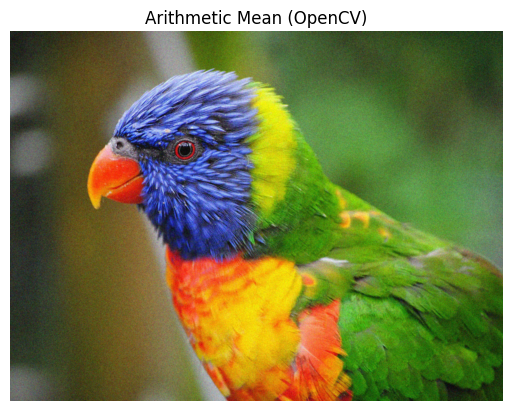

In [19]:
# Method 1: OpenCV Arithmetic Mean Filter
filtered_img = cv2.blur(noise_gauss, (3, 3))

plt.imshow(filtered_img)
plt.title('Arithmetic Mean (OpenCV)')
plt.axis('off')
plt.show()


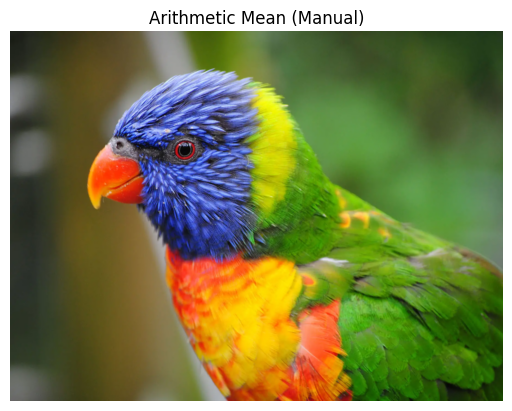

In [20]:
# Method 2: Manual Arithmetic Mean Kernel
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(img, -1, kernel)

plt.imshow(arithmetic_mean_manual)
plt.title('Arithmetic Mean (Manual)')
plt.axis('off')
plt.show()


### 3: Geometric Mean Filter

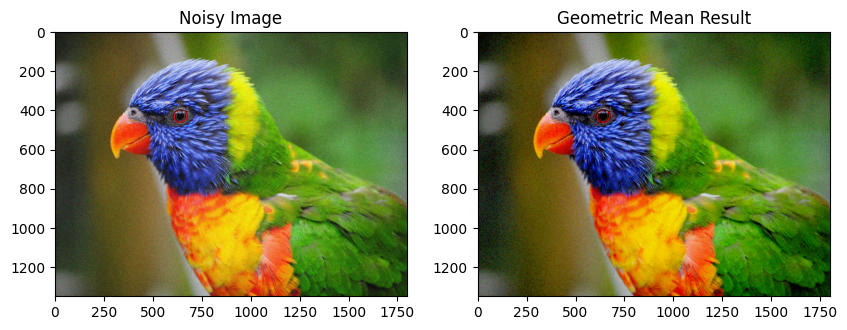

In [21]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)



noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result), plt.title('Geometric Mean Result')
plt.show()


### 4: Harmonic Mean Filter

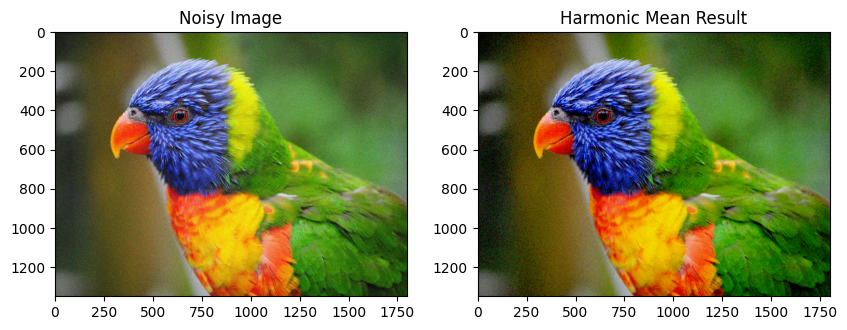

In [22]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)



noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img), plt.title('Harmonic Mean Result')
plt.show()


### 5: Contra-Harmonic Mean Filter

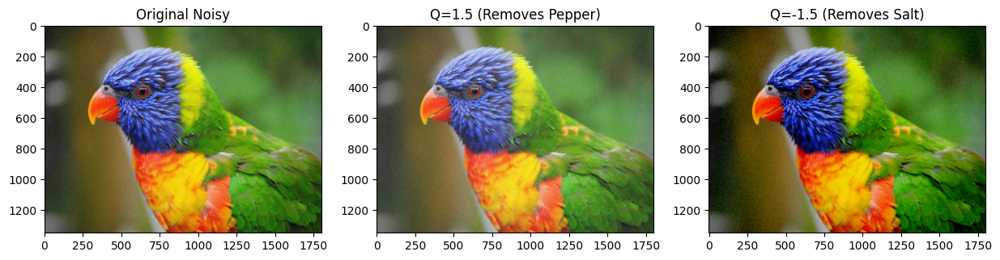

In [26]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)


noise_img = noise_gauss

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


### 6: Median Filter

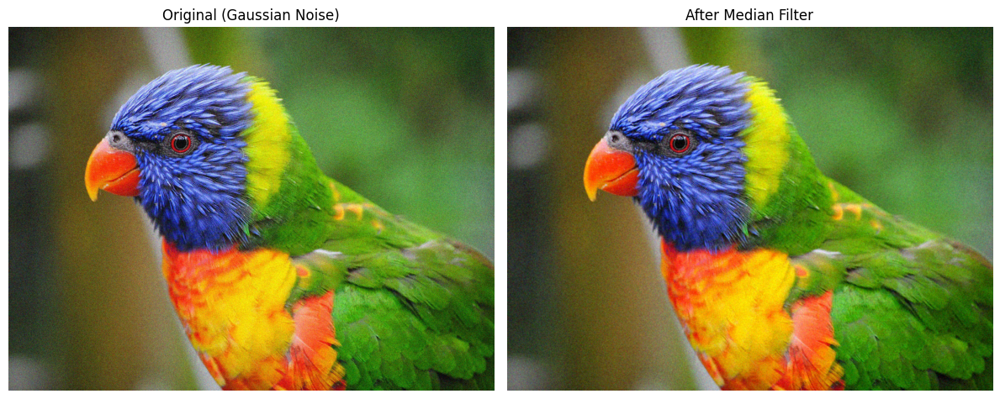

In [23]:
noise_img = noise_gauss

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img), plt.title('Original (Gaussian Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


### 7: Max and Min Filters

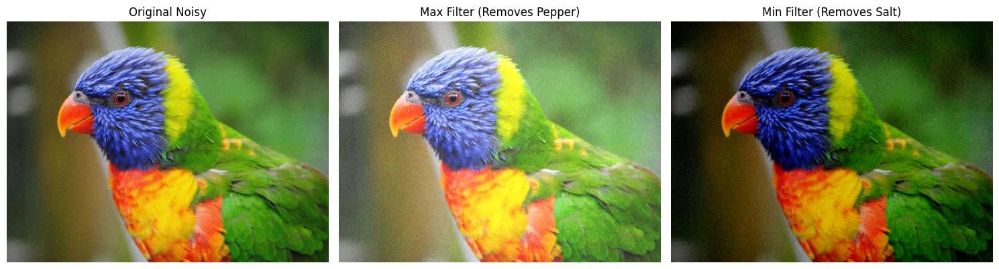

In [27]:
noise_img = noise_gauss
# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


### 8: Midpoint Filter

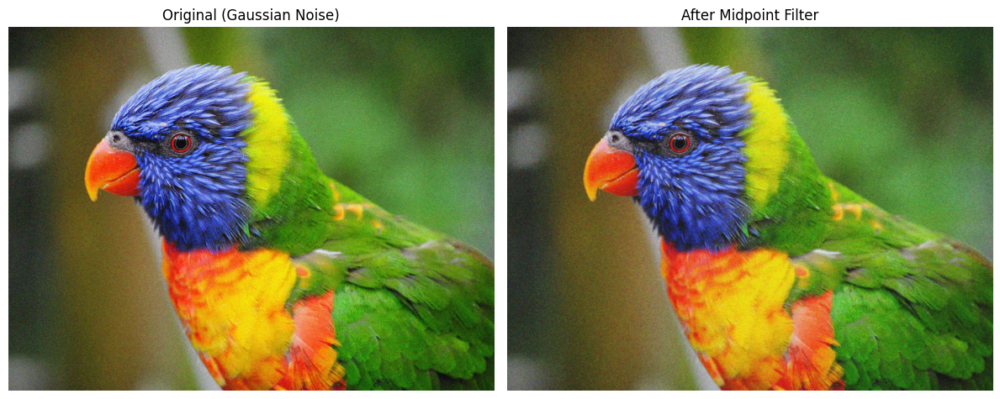

In [28]:
def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)




noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img), plt.title('Original (Gaussian Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()


---